# Modeling Human Activity States Using Hidden Markov Models

Hidden states **Z** = {standing, walking, jumping, still}. Observations **X** = feature vectors (time + frequency domain) from accelerometer and gyroscope windows. The HMM is implemented from scratch with numpy.

**Expected data layout** (relative to the repo root)

```
data/raw/        training recordings
data/test/       unseen recordings (a separate session: another day, place or phone position), never used for training
data/processed/  resampled recordings written by this notebook
```

Each recording is named `<name>_<activity>_<nn>`, e.g. `kalisa10_walking_03`, and is either
* a **folder** holding Sensor Logger's `Accelerometer.csv` and `Gyroscope.csv`, or
* a single **CSV** with columns `timestamp, ax, ay, az, gx, gy, gz`.

**Pipeline:** load and resample, window, features, standardize + PCA, HMM (supervised initialisation, Baum-Welch, Viterbi), evaluation, plots.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path(os.environ.get('HMM_DATA_DIR', '../data'))
RAW_DIR, TEST_DIR, PROC_DIR = DATA_DIR / 'raw', DATA_DIR / 'test', DATA_DIR / 'processed'
FIG_DIR = Path(os.environ.get('HMM_FIG_DIR', '../report/figures'))
FIG_DIR.mkdir(parents=True, exist_ok=True)

ACTIVITIES = ['standing', 'walking', 'jumping', 'still']
K = len(ACTIVITIES)
CHANNELS = ['ax', 'ay', 'az', 'gx', 'gy', 'gz']

TARGET_FS = 50      # Hz, common sampling rate for every member
TRIM_SEC = 1.0      # drop the start/end of each recording (tapping the phone)
# (start, end) seconds to trim for clips where the phone was moved while still starting/stopping the recording
TRIM_OVERRIDE = {'raw/kalisa10_standing_01': (1.0, 3.5),
                 'test/kalisa10_standing_01': (2.0, 2.0),
                 'test/kalisa10_still_01': (2.0, 1.0)}
WIN_SEC = 2.0       # window length
OVERLAP = 0.5       # window overlap
N_PCA = 8           # PCA components fed to the HMM
SESSION_LEN = 5     # recordings stitched into one session (gives real transitions)
N_SESSIONS = 40     # number of stitched sessions drawn per pool
BW_MAX_ITER = 200   # Baum-Welch iteration cap
BW_TOL = 1e-4       # stop when the relative log-likelihood gain falls below this
SEED = 42
rng = np.random.default_rng(SEED)

## 1. Load and harmonize sampling rates

In [2]:
def to_seconds(t):
    """Seconds since the first sample; handles ns / ms / s epoch timestamps."""
    t = np.asarray(t, dtype=float)
    scale = 1e9 if t[0] > 1e17 else 1e3 if t[0] > 1e11 else 1.0
    return (t - t[0]) / scale


def parse_name(path):
    member, activity, _ = Path(path).stem.rsplit('_', 2)
    assert activity in ACTIVITIES, f'unknown activity in {path}'
    return member, activity


def load_recording(path):
    """Return (DataFrame of the 6 channels resampled to TARGET_FS, native sampling rate, raw seconds)."""
    path = Path(path)
    if path.is_dir():                                   # Sensor Logger export
        # TotalAcceleration keeps gravity, so the mean features encode phone orientation
        # (flat on a table vs upright at the waist); Accelerometer.csv has gravity removed.
        acc_file = 'TotalAcceleration.csv' if (path / 'TotalAcceleration.csv').exists() else 'Accelerometer.csv'
        acc = pd.read_csv(path / acc_file)
        gyr = pd.read_csv(path / 'Gyroscope.csv')
        ta = acc['seconds_elapsed'].to_numpy()
        tg = gyr['seconds_elapsed'].to_numpy()
        series = {**{f'a{c}': (ta, acc[c].to_numpy()) for c in 'xyz'},
                  **{f'g{c}': (tg, gyr[c].to_numpy()) for c in 'xyz'}}
    else:                                               # merged CSV
        df = pd.read_csv(path)
        t = to_seconds(df['timestamp'])
        ta = tg = t
        series = {c: (t, df[c].to_numpy()) for c in CHANNELS}
    native_fs = 1.0 / np.median(np.diff(ta))
    trim_start, trim_end = TRIM_OVERRIDE.get(f'{path.parent.name}/{path.stem}', (TRIM_SEC, TRIM_SEC))
    start = max(ta[0], tg[0]) + trim_start
    stop = min(ta[-1], tg[-1]) - trim_end
    grid = np.arange(start, stop, 1.0 / TARGET_FS)
    out = pd.DataFrame({'timestamp': grid - grid[0]})
    for c in CHANNELS:
        out[c] = np.interp(grid, *series[c])
    return out, native_fs, ta[-1] - ta[0]


def list_recordings(folder):
    if not folder.exists():
        return []
    return sorted(p for p in folder.rglob('*')
                  if (p.is_dir() and (p / 'Accelerometer.csv').exists())
                  or (p.is_file() and p.suffix == '.csv'
                      and p.stem.count('_') >= 2 and p.name not in ('Accelerometer.csv', 'Gyroscope.csv')))


def load_pool(folder, save_to=None):
    recs, rows = [], []
    for p in list_recordings(folder):
        member, activity = parse_name(p)
        df, native_fs, raw_sec = load_recording(p)
        recs.append({'name': p.stem, 'member': member, 'activity': activity, 'data': df})
        rows.append({'name': p.stem, 'member': member, 'activity': activity,
                     'native_fs_hz': round(native_fs, 1), 'raw_seconds': round(raw_sec, 1),
                     'seconds': round(len(df) / TARGET_FS, 1)})
        if save_to is not None:
            save_to.mkdir(parents=True, exist_ok=True)
            df.to_csv(save_to / f'{p.stem}.csv', index=False)
    return recs, pd.DataFrame(rows)


train_pool, inv_train = load_pool(RAW_DIR, save_to=PROC_DIR)
test_pool, inv_test = load_pool(TEST_DIR)
print(f'{len(train_pool)} training recordings, {len(test_pool)} unseen recordings')
inv_train.groupby(['member', 'activity']).size().unstack(fill_value=0)

40 training recordings, 8 unseen recordings


activity,jumping,standing,still,walking
member,,,,
kalisa10,10,10,10,10


In [3]:
# Sampling rate of the recording phone, and how much data each activity has (for the report)
inv_all = pd.concat([inv_train.assign(pool='train'), inv_test.assign(pool='unseen')])
print('Native sampling rate (Hz) per member:')
print(inv_all.groupby('member')['native_fs_hz'].agg(['mean', 'min', 'max']).round(1))
print(f'-> every recording is linearly interpolated onto one {TARGET_FS} Hz grid '
      f'({1000 / TARGET_FS:.0f} ms spacing) after trimming {TRIM_SEC:.0f} s at each end.\n')
vol = inv_all.groupby(['activity', 'pool']).agg(files=('name', 'size'), raw_s=('raw_seconds', 'sum'),
                                               usable_s=('seconds', 'sum')).unstack('pool').round(1)
vol['total_raw_s'] = vol['raw_s'].sum(axis=1)
vol.loc[ACTIVITIES]

Native sampling rate (Hz) per member:
          mean   min   max
member                    
kalisa10  50.7  50.7  50.7
-> every recording is linearly interpolated onto one 50 Hz grid (20 ms spacing) after trimming 1 s at each end.



files         raw_s        usable_s        total_raw_s
pool     train unseen  train unseen    train unseen            
activity                                                       
standing    10      2  117.7   24.2     95.2   18.2       141.9
walking     10      2  117.6   23.8     97.6   19.8       141.4
jumping     10      2  118.4   23.9     98.4   19.9       142.3
still       10      2  118.9   24.1     98.9   19.1       143.0

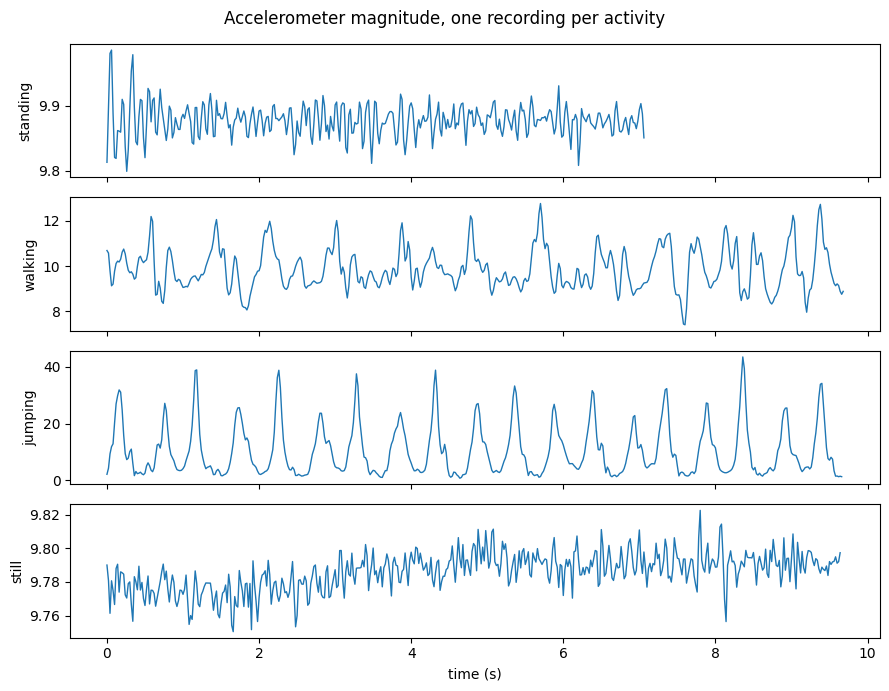

In [4]:
# Example raw signal per activity (accelerometer magnitude)
fig, axes = plt.subplots(K, 1, figsize=(9, 7), sharex=True)
for ax, act in zip(axes, ACTIVITIES):
    rec = next(r for r in train_pool if r['activity'] == act)
    d = rec['data']
    ax.plot(d['timestamp'], np.linalg.norm(d[['ax', 'ay', 'az']], axis=1), lw=1)
    ax.set_ylabel(act)
axes[-1].set_xlabel('time (s)')
fig.suptitle('Accelerometer magnitude, one recording per activity')
fig.tight_layout(); fig.savefig(FIG_DIR / 'raw_signals.png', dpi=150); plt.show()

## 2. Windowing and feature extraction

**Window size.** The phone is resampled to 50 Hz, so a 2 s window holds 100 samples. The choice follows from the sampling rate:

* The FFT resolution is 1 / 2 s = 0.5 Hz, fine enough to tell a walking cadence (about 1.5-2 Hz) from a jumping rhythm and from a flat spectrum.
* 2 s contains at least 3 steps or jumps, so each window sees whole movement cycles. A window shorter than one cycle gives unstable variance and frequency estimates.
* The Nyquist frequency is 25 Hz, well above the human-motion band of 0.3-15 Hz used below.
* A 50 % overlap (1 s hop) doubles the number of windows from short clips and keeps consecutive observations correlated, which is what an HMM expects.

**Features** (38 per window, over 6 sensor channels: ax, ay, az, gx, gy, gz)

| Feature | Domain | Why it separates the activities |
|---|---|---|
| mean per channel | time | Includes gravity, so it encodes phone orientation: flat on a table (still) vs upright at the waist (standing). |
| variance, standard deviation per channel | time | Movement intensity: about 0 for still and standing, moderate for walking, large for jumping. |
| signal magnitude area (SMA) | time | Overall activity level, independent of which axis the motion falls on. |
| correlation between axes | time | Coordination of motion: walking couples the vertical and forward axes, jumping is dominated by the vertical axis. |
| dominant frequency (FFT) | frequency | Cadence: steps and jumps repeat at different rates, a static phone has no clear peak. |
| spectral energy (FFT) | frequency | Total oscillatory power, a more noise-robust intensity measure than variance. |
| energy in 4 bands (0.3-1, 1-3, 3-6, 6-15 Hz) | frequency | Where the power sits: gait fundamental, its harmonics, and impact transients from jumps. |

In [5]:
BANDS = [(0.3, 1), (1, 3), (3, 6), (6, 15)]   # Hz


def spectrum_feats(sig, fs):
    sig = sig - sig.mean()
    spec = np.abs(np.fft.rfft(sig)) ** 2 / len(sig)
    freqs = np.fft.rfftfreq(len(sig), 1 / fs)
    dom = freqs[1:][np.argmax(spec[1:])]
    bands = [spec[(freqs >= lo) & (freqs < hi)].sum() for lo, hi in BANDS]
    return [dom, spec[1:].sum(), *bands]


def window_features(w, fs=TARGET_FS):
    acc, gyr = w[:, :3], w[:, 3:]
    f = [*w.mean(0), *w.var(0), *w.std(0)]
    for s in (acc, gyr):
        f.append(np.abs(s).sum() / len(s))                       # SMA
        with np.errstate(invalid='ignore', divide='ignore'):
            c = np.corrcoef(s.T)
        f += [c[0, 1], c[0, 2], c[1, 2]]                         # axis correlations
        f += spectrum_feats(np.linalg.norm(s, axis=1), fs)       # frequency domain
    return np.nan_to_num(np.array(f))                            # flat signal -> corr NaN -> 0


def feature_names():
    n = [f'{s}_{c}' for s in ('mean', 'var', 'std') for c in CHANNELS]
    for p in ('acc', 'gyr'):
        n += [f'{p}_sma', f'{p}_corr_xy', f'{p}_corr_xz', f'{p}_corr_yz', f'{p}_domfreq', f'{p}_energy']
        n += [f'{p}_band_{lo}-{hi}Hz' for lo, hi in BANDS]
    return n


def featurize(rec):
    x = rec['data'][CHANNELS].to_numpy()
    size, step = int(WIN_SEC * TARGET_FS), int(WIN_SEC * TARGET_FS * (1 - OVERLAP))
    X = np.array([window_features(x[i:i + size]) for i in range(0, len(x) - size + 1, step)])
    return X, np.full(len(X), ACTIVITIES.index(rec['activity']))


for r in train_pool + test_pool:
    r['X'], r['y'] = featurize(r)

FEATS = feature_names()
print(len(FEATS), 'features per window;', sum(len(r['y']) for r in train_pool), 'training windows,',
      sum(len(r['y']) for r in test_pool), 'unseen windows')

38 features per window; 328 training windows, 64 unseen windows


## 3. Train / unseen split

If `data/test/` is empty the notebook falls back to holding out 25 % of the recordings of each activity so it still runs, but **the assignment asks for genuinely new recordings** (a separate session: another day, another place or a different phone position) in `data/test/`.

In [6]:
if test_pool:
    train_recs, test_recs = train_pool, test_pool
    print('Using data/test/ as unseen data')
else:
    print('WARNING: data/test/ is empty, holding out 25% of recordings per activity')
    train_recs, test_recs = [], []
    for act in ACTIVITIES:
        pool = [r for r in train_pool if r['activity'] == act]
        idx = rng.permutation(len(pool))
        n_test = max(1, round(0.25 * len(pool)))
        test_recs += [pool[i] for i in idx[:n_test]]
        train_recs += [pool[i] for i in idx[n_test:]]


def make_sessions(recs, n_sessions, length):
    """Stitch random recordings into longer sessions so the sequence contains activity changes."""
    sessions = []
    for _ in range(n_sessions):
        pick = rng.choice(len(recs), size=min(length, len(recs)), replace=False)
        sessions.append((np.vstack([recs[i]['X'] for i in pick]),
                         np.concatenate([recs[i]['y'] for i in pick])))
    return sessions


def partition_sessions(recs, length):
    """Every recording used exactly once, so the evaluation counts each unseen window once."""
    idx = rng.permutation(len(recs))
    return [(np.vstack([recs[i]['X'] for i in idx[s:s + length]]),
             np.concatenate([recs[i]['y'] for i in idx[s:s + length]]))
            for s in range(0, len(idx), length)]


train_sessions = make_sessions(train_recs, N_SESSIONS, SESSION_LEN)
test_sessions = partition_sessions(test_recs, 4)
print(len(train_recs), 'train recordings ->', len(train_sessions), 'sessions;',
      len(test_recs), 'unseen recordings ->', len(test_sessions), 'sessions')

Using data/test/ as unseen data
40 train recordings -> 40 sessions; 8 unseen recordings -> 2 sessions


## 4. Standardize and reduce (fitted on training windows only)

* **Z-score standardisation** (subtract the training mean, divide by the training standard deviation). The 38 features have different units (m/s², rad/s, Hz) and ranges that differ by orders of magnitude, so without scaling the high-variance features (spectral energy) would dominate the PCA and the Gaussian emissions. Z-scores assume no fixed range, unlike min-max scaling, which a single jump impact would distort.
* The mean and standard deviation come from the **training windows only** and are re-used on the unseen data, so no information leaks from the test set.
* **PCA to 8 components** removes the strong correlations between features (mean, variance and band energy of the same channel), so one full-covariance Gaussian per state can be estimated from a small number of windows.

In [7]:
Xtr_all = np.vstack([r['X'] for r in train_recs])
mu, sd = Xtr_all.mean(0), Xtr_all.std(0) + 1e-9
_, S, Vt = np.linalg.svd((Xtr_all - mu) / sd, full_matrices=False)
W = Vt[:N_PCA].T
print(f'PCA keeps {100 * (S[:N_PCA] ** 2).sum() / (S ** 2).sum():.1f}% of the variance')


def transform(X):
    return ((X - mu) / sd) @ W


train_sessions = [(transform(X), y) for X, y in train_sessions]
test_sessions = [(transform(X), y) for X, y in test_sessions]

PCA keeps 82.9% of the variance


## 5. Hidden Markov Model from scratch

* **Z**: the 4 activities, **X**: PCA feature vectors, **π**: initial state probabilities, **A**: transition matrix, **B**: one multivariate Gaussian per activity.
* **Supervised initialisation** (`fit`): the labels are known, so π, A, μ and Σ are first estimated by counting and Gaussian moments (maximum likelihood with additive smoothing).
* **Baum-Welch** (`baum_welch`): EM that re-estimates π, A, μ and Σ from the observations alone using the forward-backward algorithm. Each iteration computes the training log-likelihood. It stops when the relative gain falls below `BW_TOL` (convergence criterion) or after `BW_MAX_ITER` iterations.
* **Viterbi** (log-space) decodes the single most likely activity sequence, which is what sensitivity and specificity are computed from. **Forward-Backward** gives per-window posteriors (confidence).

In [8]:
def logsumexp(a, axis=None):
    m = np.max(a, axis=axis, keepdims=True)
    out = m + np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True))
    return out.item() if axis is None else np.squeeze(out, axis=axis)


class GaussianHMM:
    """K-state HMM with a full-covariance Gaussian emission per state; every recursion runs in log space."""

    def __init__(self, n_states, smooth=1.0, reg=1e-2):
        self.K, self.smooth, self.reg = n_states, smooth, reg

    def fit(self, sessions):
        """Supervised estimation from labelled sessions [(X, y), ...] by counting."""
        D = sessions[0][0].shape[1]
        pi = np.full(self.K, self.smooth)
        A = np.full((self.K, self.K), self.smooth)
        for X, y in sessions:
            pi[y[0]] += 1
            np.add.at(A, (y[:-1], y[1:]), 1)
        self.pi, self.A = pi / pi.sum(), A / A.sum(1, keepdims=True)
        Xall, yall = np.vstack([s[0] for s in sessions]), np.concatenate([s[1] for s in sessions])
        self.mu = np.array([Xall[yall == k].mean(0) for k in range(self.K)])
        self.cov = np.array([np.cov(Xall[yall == k].T) + self.reg * np.eye(D) for k in range(self.K)])
        return self

    def copy_from(self, other):
        self.pi, self.A, self.mu, self.cov = other.pi.copy(), other.A.copy(), other.mu.copy(), other.cov.copy()
        return self

    def log_emission(self, X):
        T, D = X.shape
        out = np.empty((T, self.K))
        for k in range(self.K):
            L = np.linalg.cholesky(self.cov[k])
            z = np.linalg.solve(L, (X - self.mu[k]).T)
            out[:, k] = -0.5 * (z ** 2).sum(0) - np.log(np.diag(L)).sum() - 0.5 * D * np.log(2 * np.pi)
        return out

    def forward_backward(self, X):
        """Return log P(X), state posteriors gamma (T, K) and expected transition counts xi (K, K)."""
        logB, logA = self.log_emission(X), np.log(self.A)
        T = len(X)
        la, lb = np.empty((T, self.K)), np.zeros((T, self.K))
        la[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            la[t] = logsumexp(la[t - 1][:, None] + logA, axis=0) + logB[t]
        for t in range(T - 2, -1, -1):
            lb[t] = logsumexp(logA + logB[t + 1] + lb[t + 1], axis=1)
        ll = logsumexp(la[-1])
        gamma = np.exp(la + lb - ll)
        xi = np.zeros((self.K, self.K))
        for t in range(T - 1):
            xi += np.exp(la[t][:, None] + logA + logB[t + 1] + lb[t + 1] - ll)
        return ll, gamma, xi

    def posteriors(self, X):
        return self.forward_backward(X)[1]

    def baum_welch(self, sequences, max_iter=200, tol=1e-4, verbose=True):
        """EM on unlabelled sequences [X, ...]. Stops when |LL_new - LL_old| < tol * |LL_old|.

        Returns the training log-likelihood at the start of each iteration."""
        D = sequences[0].shape[1]
        history = []
        for it in range(max_iter):
            pi_s, xi_s = np.zeros(self.K), np.zeros((self.K, self.K))
            S0, S1, S2 = np.zeros(self.K), np.zeros((self.K, D)), np.zeros((self.K, D, D))
            total = 0.0
            for X in sequences:                                  # E-step
                ll, g, xi = self.forward_backward(X)
                total += ll
                pi_s += g[0]
                xi_s += xi
                S0 += g.sum(0)
                S1 += g.T @ X
                S2 += np.einsum('tk,td,te->kde', g, X, X)
            history.append(total)
            if it > 0 and abs(total - history[-2]) < tol * abs(history[-2]):
                if verbose:
                    print(f'Baum-Welch converged after {it + 1} iterations, log-likelihood {total:.2f}')
                break
            pi_s += 1e-3
            xi_s += 1e-3                                         # M-step
            self.pi, self.A = pi_s / pi_s.sum(), xi_s / xi_s.sum(1, keepdims=True)
            self.mu = S1 / S0[:, None]
            self.cov = S2 / S0[:, None, None] - np.einsum('kd,ke->kde', self.mu, self.mu) + self.reg * np.eye(D)
        else:
            if verbose:
                print(f'Baum-Welch reached max_iter={max_iter}, log-likelihood {total:.2f}')
        return history

    def viterbi(self, X):
        logB, logA = self.log_emission(X), np.log(self.A)
        T = len(X)
        delta, psi = np.empty((T, self.K)), np.zeros((T, self.K), dtype=int)
        delta[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            scores = delta[t - 1][:, None] + logA
            psi[t] = scores.argmax(0)
            delta[t] = scores.max(0) + logB[t]
        path = np.empty(T, dtype=int)
        path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path


hmm_sup = GaussianHMM(K).fit(train_sessions)
print('supervised pi =', dict(zip(ACTIVITIES, hmm_sup.pi.round(3))))

supervised pi = {'standing': 0.227, 'walking': 0.295, 'jumping': 0.25, 'still': 0.227}


### Baum-Welch training

The supervised estimates are the starting point. Baum-Welch then refines π, A, μ and Σ on the training sequences **without looking at the labels**, maximising P(X | model). The convergence plot shows the training log-likelihood per iteration. We also run Baum-Welch from a label-free **k-means** initialisation (states are mapped to activities afterwards) to show that the algorithm recovers the structure from the signals alone.

Baum-Welch converged after 6 iterations, log-likelihood -10876.37


Baum-Welch converged after 9 iterations, log-likelihood -10760.77


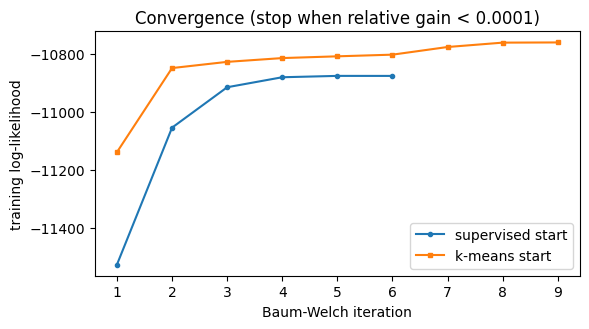

In [9]:
from scipy.optimize import linear_sum_assignment

train_X = [X for X, _ in train_sessions]

# (a) supervised start -> Baum-Welch refinement (the final model used below)
hmm = GaussianHMM(K).copy_from(hmm_sup)
ll_sup = hmm.baum_welch(train_X, max_iter=BW_MAX_ITER, tol=BW_TOL)


# (b) label-free k-means start -> Baum-Welch
def kmeans(X, k, iters=50):
    c = X[rng.choice(len(X), k, replace=False)]
    for _ in range(iters):
        lab = np.argmin(((X[:, None] - c[None]) ** 2).sum(-1), axis=1)
        c = np.array([X[lab == j].mean(0) if (lab == j).any() else c[j] for j in range(k)])
    return lab


lab = kmeans(np.vstack(train_X), K)
pos = np.cumsum([0] + [len(X) for X in train_X])
hmm_unsup = GaussianHMM(K).fit([(X, lab[a:b]) for X, a, b in zip(train_X, pos[:-1], pos[1:])])
ll_unsup = hmm_unsup.baum_welch(train_X, max_iter=BW_MAX_ITER, tol=BW_TOL)
# map each hidden state to the activity it overlaps most (Hungarian assignment on the training labels)
y_train = np.concatenate([y for _, y in train_sessions])
dec = np.concatenate([hmm_unsup.viterbi(X) for X in train_X])
overlap = np.zeros((K, K), dtype=int)
np.add.at(overlap, (dec, y_train), 1)
rows, cols = linear_sum_assignment(-overlap)
state_to_act = np.array([c for _, c in sorted(zip(rows, cols))])

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(range(1, len(ll_sup) + 1), ll_sup, 'o-', ms=3, label='supervised start')
ax.plot(range(1, len(ll_unsup) + 1), ll_unsup, 's-', ms=3, label='k-means start')
ax.set_xlabel('Baum-Welch iteration'); ax.set_ylabel('training log-likelihood'); ax.legend()
ax.set_title(f'Convergence (stop when relative gain < {BW_TOL:g})')
fig.tight_layout(); fig.savefig(FIG_DIR / 'baum_welch_convergence.png', dpi=150); plt.show()

## 6. Transition matrix heatmap

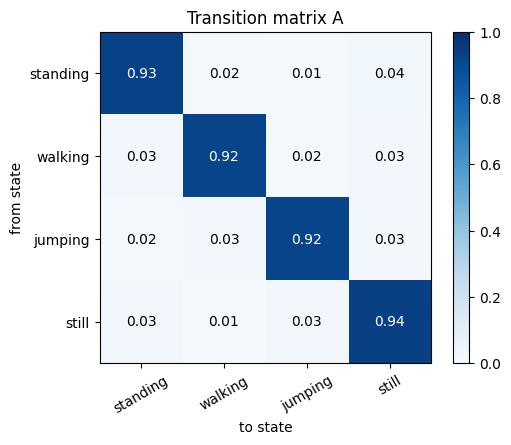

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(hmm.A, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(K), ACTIVITIES, rotation=30); ax.set_yticks(range(K), ACTIVITIES)
for i in range(K):
    for j in range(K):
        ax.text(j, i, f'{hmm.A[i, j]:.2f}', ha='center', va='center',
                color='white' if hmm.A[i, j] > 0.5 else 'black')
ax.set_xlabel('to state'); ax.set_ylabel('from state'); ax.set_title('Transition matrix A')
fig.colorbar(im); fig.tight_layout(); fig.savefig(FIG_DIR / 'transition_matrix.png', dpi=150); plt.show()

## 6b. Emission probabilities B

Each state emits PCA feature vectors from its own Gaussian. The left panel shows the state means (rows) on the 8 principal components; the right panel shows the fitted emission density on the first component, with the training windows as histograms.

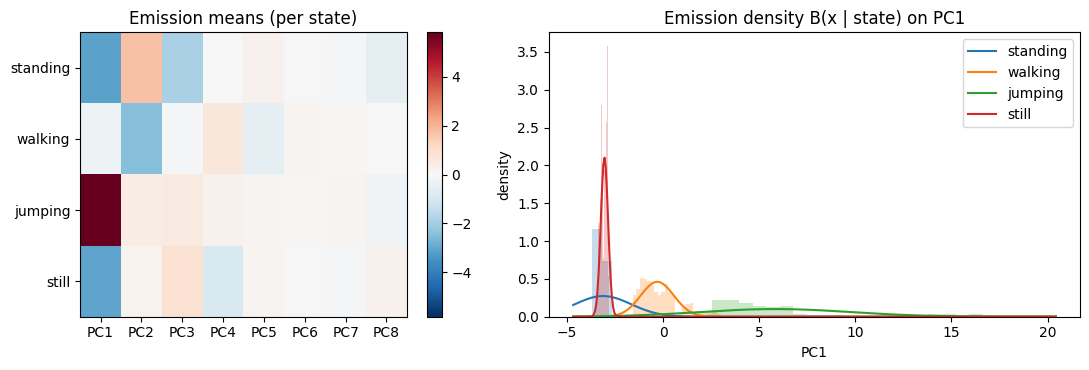

In [11]:
from scipy.stats import norm

Xtr_pc = np.vstack(train_X)
ytr_pc = np.concatenate([y for _, y in train_sessions])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={'width_ratios': [1, 1.3]})
lim = np.abs(hmm.mu).max()
im = a1.imshow(hmm.mu, cmap='RdBu_r', aspect='auto', vmin=-lim, vmax=lim)
a1.set_yticks(range(K), ACTIVITIES); a1.set_xticks(range(N_PCA), [f'PC{i + 1}' for i in range(N_PCA)])
a1.set_title('Emission means (per state)'); fig.colorbar(im, ax=a1)
grid = np.linspace(Xtr_pc[:, 0].min() - 1, Xtr_pc[:, 0].max() + 1, 400)
for k, act in enumerate(ACTIVITIES):
    a2.hist(Xtr_pc[ytr_pc == k, 0], bins=25, density=True, alpha=0.25, color=f'C{k}')
    a2.plot(grid, norm.pdf(grid, hmm.mu[k, 0], np.sqrt(hmm.cov[k, 0, 0])), color=f'C{k}', label=act)
a2.set_xlabel('PC1'); a2.set_ylabel('density'); a2.set_title('Emission density B(x | state) on PC1'); a2.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / 'emission_probabilities.png', dpi=150); plt.show()

## 7. Evaluation on unseen data

Sensitivity, specificity and accuracy are computed **one-vs-rest** per activity from the confusion matrix of Viterbi-decoded windows. A frame-by-frame Gaussian classifier (no transitions) is shown as a baseline to measure what the HMM's transition structure adds.

In [12]:
def confusion(y_true, y_pred):
    C = np.zeros((K, K), dtype=int)
    np.add.at(C, (y_true, y_pred), 1)
    return C


def metrics_table(C):
    rows, N = [], C.sum()
    for k, act in enumerate(ACTIVITIES):
        TP = C[k, k]; FN = C[k].sum() - TP; FP = C[:, k].sum() - TP; TN = N - TP - FN - FP
        rows.append({'State (Activity)': act, 'Number of Samples': int(C[k].sum()),
                     'Sensitivity': TP / (TP + FN) if TP + FN else np.nan,
                     'Specificity': TN / (TN + FP) if TN + FP else np.nan,
                     'Overall Accuracy': (TP + TN) / N})
    df = pd.DataFrame(rows)
    df.loc[len(df)] = ['ALL (overall accuracy)', int(N), np.nan, np.nan, np.trace(C) / N]
    return df


y_true = np.concatenate([y for _, y in test_sessions])
y_hmm = np.concatenate([hmm.viterbi(X) for X, _ in test_sessions])
y_frame = np.concatenate([hmm.log_emission(X).argmax(1) for X, _ in test_sessions])

C_hmm = confusion(y_true, y_hmm)
table = metrics_table(C_hmm)
table.to_csv(FIG_DIR / 'metrics_table.csv', index=False)
print(f'HMM (Viterbi) accuracy: {np.trace(C_hmm) / C_hmm.sum():.3f}   '
      f'frame-wise Gaussian baseline: {(y_frame == y_true).mean():.3f}')
table.round(3)

HMM (Viterbi) accuracy: 1.000   frame-wise Gaussian baseline: 0.984


,State (Activity),Number of Samples,Sensitivity,Specificity,Overall Accuracy
0,standing,15,1.0,1.0,1.0
1,walking,17,1.0,1.0,1.0
2,jumping,16,1.0,1.0,1.0
3,still,16,1.0,1.0,1.0
4,ALL (overall accuracy),64,NaN,NaN,1.0


In [13]:
# Compare: frame-wise Gaussian (no transitions), supervised HMM, Baum-Welch HMM, label-free Baum-Welch HMM
def decode_all(model):
    return np.concatenate([model.viterbi(X) for X, _ in test_sessions])


y_unsup = state_to_act[decode_all(hmm_unsup)]
comparison = pd.DataFrame({
    'model': ['frame-wise Gaussian (no A)', 'HMM, supervised counts + Viterbi',
              'HMM, supervised start + Baum-Welch + Viterbi', 'HMM, k-means start + Baum-Welch + Viterbi'],
    'unseen accuracy': [(y_frame == y_true).mean(), (decode_all(hmm_sup) == y_true).mean(),
                        (y_hmm == y_true).mean(), (y_unsup == y_true).mean()]}).round(3)
comparison.to_csv(FIG_DIR / 'model_comparison.csv', index=False)
comparison

,model,unseen accuracy
0,frame-wise Gaussian (no A),0.984
1,"HMM, supervised counts + Viterbi",0.984
2,"HMM, supervised start + Baum-Welch + Viterbi",1.000
3,"HMM, k-means start + Baum-Welch + Viterbi",1.000


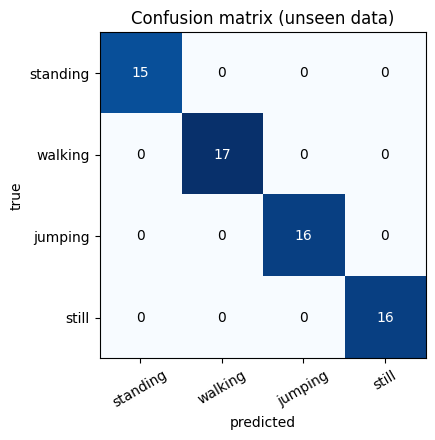

In [14]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(C_hmm, cmap='Blues')
ax.set_xticks(range(K), ACTIVITIES, rotation=30); ax.set_yticks(range(K), ACTIVITIES)
for i in range(K):
    for j in range(K):
        ax.text(j, i, C_hmm[i, j], ha='center', va='center',
                color='white' if C_hmm[i, j] > C_hmm.max() / 2 else 'black')
ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title('Confusion matrix (unseen data)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'confusion_matrix.png', dpi=150); plt.show()

## 8. Decoded sequences

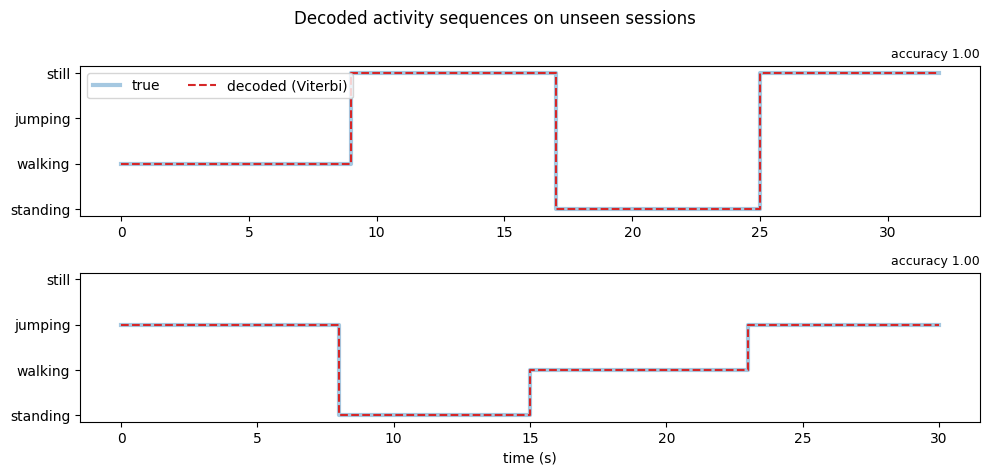

In [15]:
n_show = min(3, len(test_sessions))
fig, axes = plt.subplots(n_show, 1, figsize=(10, 2.4 * n_show), sharey=True, squeeze=False)
for ax, (X, y) in zip(axes[:, 0], test_sessions[:n_show]):
    pred = hmm.viterbi(X)
    t = np.arange(len(y)) * WIN_SEC * (1 - OVERLAP)
    ax.step(t, y, where='post', lw=3, alpha=0.4, label='true')
    ax.step(t, pred, where='post', lw=1.5, ls='--', color='tab:red', label='decoded (Viterbi)')
    ax.set_yticks(range(K), ACTIVITIES)
    ax.set_title(f'accuracy {(pred == y).mean():.2f}', fontsize=9, loc='right')
axes[0, 0].legend(loc='upper left', ncol=2); axes[-1, 0].set_xlabel('time (s)')
fig.suptitle('Decoded activity sequences on unseen sessions')
fig.tight_layout(); fig.savefig(FIG_DIR / 'decoded_sequences.png', dpi=150); plt.show()

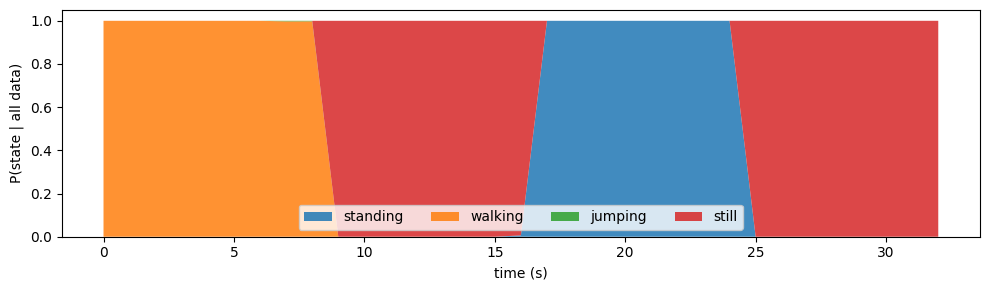

In [16]:
# Forward-Backward posteriors: how confident is the model along one session?
X, y = test_sessions[0]
post = hmm.posteriors(X)
fig, ax = plt.subplots(figsize=(10, 3))
ax.stackplot(np.arange(len(y)) * WIN_SEC * (1 - OVERLAP), post.T, labels=ACTIVITIES, alpha=0.85)
ax.set_xlabel('time (s)'); ax.set_ylabel('P(state | all data)'); ax.legend(ncol=4, loc='lower center')
fig.tight_layout(); fig.savefig(FIG_DIR / 'posteriors.png', dpi=150); plt.show()

In [17]:
# Key numbers quoted in the report
np.set_printoptions(precision=3, suppress=True)
print('pi =', dict(zip(ACTIVITIES, hmm.pi.round(3))))
print('A (rows = from, cols = to):'); print(hmm.A)
print('confusion matrix (rows = true, cols = predicted):'); print(C_hmm)
Xf = np.vstack([r['X'] for r in train_pool]); yf = np.concatenate([r['y'] for r in train_pool])
cols = ['acc_domfreq', 'gyr_domfreq', 'acc_sma', 'acc_energy']
print(pd.DataFrame({c: [Xf[yf == k, FEATS.index(c)].mean() for k in range(K)] for c in cols}, index=ACTIVITIES).round(3))
print('posterior confidence (mean max gamma) on unseen:',
      np.mean(np.concatenate([hmm.posteriors(X).max(1) for X, _ in test_sessions])).round(3))
print('Viterbi errors:', [(ACTIVITIES[t], ACTIVITIES[p]) for t, p in zip(y_true, y_hmm) if t != p])

pi = {'standing': 0.15, 'walking': 0.3, 'jumping': 0.25, 'still': 0.3}
A (rows = from, cols = to):
[[0.93  0.019 0.014 0.038]
 [0.028 0.922 0.022 0.028]
 [0.02  0.031 0.921 0.028]
 [0.026 0.01  0.028 0.935]]
confusion matrix (rows = true, cols = predicted):
[[15  0  0  0]
 [ 0 17  0  0]
 [ 0  0 16  0]
 [ 0  0  0 16]]
          acc_domfreq  gyr_domfreq  acc_sma  acc_energy
standing        8.119        1.588   11.313       1.902
walking         1.878        1.122   12.432     158.924
jumping         2.042        1.904   13.843    5584.186
still           5.175        5.470   10.134       0.005
posterior confidence (mean max gamma) on unseen: 0.999
Viterbi errors: []


## 8b. Correctness checks of the HMM code

Small automated tests: probabilities are valid, Viterbi finds the same path as brute-force enumeration, forward-backward posteriors are proper distributions, and the Baum-Welch log-likelihood increases (any dip stays below the convergence tolerance).

In [18]:
import itertools

assert np.isclose(hmm.pi.sum(), 1) and np.allclose(hmm.A.sum(1), 1), 'pi / A rows must sum to 1'

# Viterbi == brute force over all K**T paths on a short sequence
Xs = test_sessions[0][0][:6]
logB, logA, logpi = hmm.log_emission(Xs), np.log(hmm.A), np.log(hmm.pi)
def path_score(p):
    return logpi[p[0]] + logB[0, p[0]] + sum(logA[p[t - 1], p[t]] + logB[t, p[t]] for t in range(1, len(p)))
best = max(itertools.product(range(K), repeat=len(Xs)), key=path_score)
assert list(hmm.viterbi(Xs)) == list(best), 'Viterbi differs from brute force'

# forward-backward posteriors sum to 1 in every window; likelihood from the forward pass is finite
assert np.allclose(hmm.posteriors(test_sessions[0][0]).sum(1), 1)

# Baum-Welch increases the training log-likelihood. The covariance regulariser (reg * I) makes the M-step slightly
# non-exact EM, so a decrease is allowed only if it is smaller than the convergence tolerance BW_TOL itself.
for name, h in [('supervised start', ll_sup), ('k-means start', ll_unsup)]:
    assert all(b >= a - BW_TOL * abs(a) for a, b in zip(h, h[1:])), f'log-likelihood decreased ({name})'
    assert h[-1] > h[0], f'no improvement ({name})'
print('all checks passed: valid pi/A, Viterbi == brute force, posteriors normalised, Baum-Welch improves the likelihood')

all checks passed: valid pi/A, Viterbi == brute force, posteriors normalised, Baum-Welch improves the likelihood


## 8c. Cross-session check

The training clips come from two recording sessions (26 Oct: clips 01-05, 29 Oct: clips 06-10). To test generalisation across days, the whole pipeline (standardise, PCA, supervised fit, Baum-Welch, Viterbi) is re-run training on one session and testing on the other, in both directions.

In [19]:
def run_pipeline(tr, te):
    """Standardise + PCA on `tr`, supervised fit + Baum-Welch, Viterbi accuracy on `te` (per-window)."""
    Xa = np.vstack([r['X'] for r in tr])
    m, s = Xa.mean(0), Xa.std(0) + 1e-9
    Vt_ = np.linalg.svd((Xa - m) / s, full_matrices=False)[2]
    Wp = Vt_[:N_PCA].T
    tf = lambda X: ((X - m) / s) @ Wp
    sess = [(tf(X), y) for X, y in make_sessions(tr, N_SESSIONS, SESSION_LEN)]
    model = GaussianHMM(K).fit(sess)
    model.baum_welch([X for X, _ in sess], max_iter=BW_MAX_ITER, tol=BW_TOL, verbose=False)
    ts = [(tf(X), y) for X, y in partition_sessions(te, 4)]
    yt = np.concatenate([y for _, y in ts])
    yp = np.concatenate([model.viterbi(X) for X, _ in ts])
    C = confusion(yt, yp)
    return pd.Series({'train clips': len(tr), 'test clips': len(te), 'test windows': len(yt),
                      'accuracy': np.trace(C) / C.sum(),
                      **{f'sens {a}': C[i, i] / C[i].sum() for i, a in enumerate(ACTIVITIES)}})


day1 = [r for r in train_pool if int(r['name'].rsplit('_', 1)[1]) <= 5]
day2 = [r for r in train_pool if int(r['name'].rsplit('_', 1)[1]) >= 6]
cross = pd.DataFrame({'train 26 Oct -> test 29 Oct': run_pipeline(day1, day2),
                      'train 29 Oct -> test 26 Oct': run_pipeline(day2, day1)}).T.round(3)
cross.to_csv(FIG_DIR / 'cross_session.csv')
cross

,train clips,test clips,test windows,accuracy,sens standing,sens walking,sens jumping,sens still
train 26 Oct -> test 29 Oct,20.0,20.0,164.0,0.780,0.439,0.675,1.0,1.000
train 29 Oct -> test 26 Oct,20.0,20.0,164.0,0.939,0.872,0.905,1.0,0.976


## 9. Summary

* Sensitivity, specificity and accuracy per activity are in the table of section 7 and in `report/figures/metrics_table.csv`; the model comparison is in `report/figures/model_comparison.csv`.
* The interpretation (easiest and hardest activities, transition probabilities, effect of noise and sampling rate, improvements) is written in `report/report.md`.
* Caveat on **A**: the sessions are stitched from separate recordings, so the between-activity transition probabilities describe how the sessions were assembled, not real behaviour.